# EE3703 Person 3 — YOLOv2 with ResNet-18

**Work in progress - 3 November 2026:** A 10-epoch baseline has completed on 358 training images and 92 validation images. Validation mAP@0.50 was 0.0 in every epoch. Detection performance needs investigation before final model delivery. The separate 50-image original test split has not been evaluated.

The three labels, in order, are **drill, scissor, screwdriver**. The agreed backbone is ResNet-18. This is a YOLOv2-style implementation with anchor clustering, bounded centre predictions, stride-16 passthrough, stride-32 detection grid, class-wise NMS and a documented detection loss. The backbone and head are implemented from fundamental PyTorch layers and start with random weights. No Ultralytics detector, downloaded detector weights or pretrained backbone is used.

Sources: [YOLOv2 paper](https://arxiv.org/abs/1612.08242), [ResNet paper](https://arxiv.org/abs/1512.03385), and the team repository.

This adapts YOLOv2 to the proposal's backbone; it is not a byte-for-byte Darknet-19 reproduction. Loss uses BCE for centre offsets, squared error for log-size/confidence, and class cross-entropy. AP uses all-points interpolation; `map50_95` is **not** the official COCO 101-point evaluator. Only flip, brightness and contrast augmentation are enabled; additional proposed augmentation remains optional work.

Saved outputs below document the completed Colab run. The appended smoke and baseline cells execute training when run; they are not controlled by RUN_SEARCH, RUN_TRAINING or RUN_GOLD_TEST. Running all cells will therefore repeat training in a newly created run directory. PROJECT_DIR points to the original operator's Drive folder and must be set to the receiving user's data location. See PERSON3_README.md before rerunning.

In [7]:
from pathlib import Path
from datetime import datetime
from google.colab import drive
import csv
import json
import tempfile
import zipfile

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/EE3703GroupProject_person3_yolov2"
)
ZIP_PATH = PROJECT_DIR / "dataset.zip"

assert PROJECT_DIR.is_dir(), f"Project folder not found: {PROJECT_DIR}"
assert ZIP_PATH.is_file(), f"Dataset archive not found: {ZIP_PATH}"

work_dir = Path(tempfile.mkdtemp(prefix="ee3703_", dir="/content"))

with zipfile.ZipFile(ZIP_PATH) as archive:
    for member in archive.infolist():
        target = (work_dir / member.filename).resolve()
        if not target.is_relative_to(work_dir.resolve()):
            raise ValueError("Unsafe archive path")
    archive.extractall(work_dir)

PREP_DATA_ROOT = work_dir / "dataset"
csv_path = PREP_DATA_ROOT / "manifest.csv"

assert csv_path.is_file(), f"Manifest CSV not found: {csv_path}"

manifest_data = {
    "classes": ["drill", "scissor", "screwdriver"],
    "splits": {"train": [], "val": [], "test": []},
}
split_map = {"train": "train", "valid": "val", "test": "test"}

with csv_path.open(encoding="utf-8-sig", newline="") as handle:
    for row in csv.DictReader(handle):
        folder = row["split"].strip()
        split = split_map[folder]
        name = row["file_name"].strip()
        group = row["capture_group"].strip()

        assert name == Path(name).name, f"Invalid filename: {name}"
        assert group, f"Missing capture group: {name}"

        record = {
            "image": f"{folder}/images/{name}",
            "label": f"{folder}/labels/{Path(name).stem}.txt",
            "source": row["origin"].strip(),
            "scene_group": group,
        }

        for key in ("image", "label"):
            path = PREP_DATA_ROOT / record[key]
            assert path.is_file(), f"Missing file: {path}"

        manifest_data["splits"][split].append(record)

counts = {
    split: len(records)
    for split, records in manifest_data["splits"].items()
}
assert counts == {"train": 358, "val": 92, "test": 50}, counts

(PREP_DATA_ROOT / "manifest.json").write_text(
    json.dumps(manifest_data, indent=2),
    encoding="utf-8",
)

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
PREP_RUN_ROOT = PROJECT_DIR / "runs" / f"yolov2_{run_id}"
PREP_RUN_ROOT.mkdir(parents=True, exist_ok=False)

print("Dataset:", PREP_DATA_ROOT)
print("Split counts:", counts)
print("Results:", PREP_RUN_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/ee3703_2biu94_d/dataset
Split counts: {'train': 358, 'val': 92, 'test': 50}
Results: /content/drive/MyDrive/EE3703GroupProject_person3_yolov2/runs/yolov2_20261103_090954_809552


In [8]:
import sys, platform
from importlib.metadata import version
print('Python:', platform.python_version())
for package in ['torch','numpy','Pillow','matplotlib']:
    try: print(package, version(package))
    except Exception: print(package, 'missing: install before continuing')

Python: 3.13.16
torch 2.11.0+cu130
numpy 2.4.6
Pillow 11.3.0
matplotlib 3.10.0


## Imports and reproducibility

In [9]:
import copy, csv, hashlib, json, math, random, time
from pathlib import Path
import numpy as np
from PIL import Image, ImageEnhance, ImageOps
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

CLASSES = ('drill', 'scissor', 'screwdriver')
SEED = 288275

def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

def xywh_to_xyxy(x):
    return torch.cat((x[..., :2]-x[..., 2:]/2, x[..., :2]+x[..., 2:]/2), -1)

def box_iou(a,b):
    inter=(torch.minimum(a[:,None,2:],b[None,:,2:])-torch.maximum(a[:,None,:2],b[None,:,:2])).clamp(min=0).prod(-1)
    area_a=(a[:,2:]-a[:,:2]).clamp(min=0).prod(-1)
    area_b=(b[:,2:]-b[:,:2]).clamp(min=0).prod(-1)
    return inter/(area_a[:,None]+area_b[None,:]-inter+1e-9)

def wh_iou(a,b):
    inter=torch.minimum(a[:,None],b[None]).prod(-1)
    return inter/(a.prod(-1)[:,None]+b.prod(-1)[None]-inter+1e-9)

## Dataset contract and leakage audit

In [10]:
def safe_path(root, relative):
    p=(root/relative).resolve()
    if not p.is_relative_to(root.resolve()): raise ValueError('Path escapes dataset root')
    return p

def read_labels(path):
    rows=[]
    for line in path.read_text().splitlines():
        if not line.strip(): continue
        v=list(map(float,line.split()))
        if len(v)!=5 or not all(math.isfinite(x) for x in v): raise ValueError(f'Bad label: {path}')
        c,x,y,w,h=v
        if c!=int(c) or not 0<=c<len(CLASSES) or min(w,h)<=0 or max(w,h)>1:
            raise ValueError(f'Invalid class/box in {path}')
        if x-w/2 < -1e-5 or y-h/2 < -1e-5 or x+w/2>1.00001 or y+h/2>1.00001:
            raise ValueError(f'Box outside image: {path}')
        rows.append(v)
    return torch.tensor(rows,dtype=torch.float32).reshape(-1,5)

def audit_manifest(root):
    root=Path(root); m=json.loads((root/'manifest.json').read_text())
    if tuple(m['classes'])!=CLASSES: raise ValueError('Class order must be drill, scissor, screwdriver')
    seen_images=set();seen_hashes={};scene_split={};counts={};train_wh=[]
    for split in ['train','val','test']:
        records=m['splits'][split]; totals=np.zeros(3,dtype=int)
        for r in records:
            if r['source'] not in ['original','public']:raise ValueError('source must be original/public')
            if split=='test' and r['source']!='original':raise ValueError('Gold test must be original')
            p=safe_path(root,r['image']);lab=safe_path(root,r['label'])
            if str(p) in seen_images:raise ValueError('Image reused across records/splits')
            seen_images.add(str(p));labels=read_labels(lab)
            if not len(labels):raise ValueError('Tool photos require reviewed boxes, not empty placeholders')
            digest=hashlib.sha256(p.read_bytes()).hexdigest()
            if digest in seen_hashes:raise ValueError('Exact duplicate images found')
            seen_hashes[digest]=split
            group=r.get('scene_group')
            if not group:raise ValueError('Each record needs reviewed scene_group for burst/near-duplicate isolation')
            if group in scene_split and scene_split[group]!=split:raise ValueError('Scene group crosses splits')
            scene_split[group]=split
            with Image.open(p) as im:
                # Annotation coordinates refer to the EXIF-transposed image.
                im=ImageOps.exif_transpose(im);im.load();w,h=im.size
                if split=='train':train_wh.extend((labels[:,3:5]*torch.tensor([w,h])/max(w,h)).tolist())
            totals+=np.bincount(labels[:,0].long().numpy(),minlength=3)
        counts[split]={'images':len(records),'instances':totals.tolist(),'original':sum(r['source']=='original' for r in records)}
        if not records or min(totals)==0:raise ValueError(f'{split}: all three classes must be represented')
    if counts['test']['images']!=50:raise ValueError('Exactly 50 untouched original test images required')
    if counts['train']['original']+counts['val']['original']<50:raise ValueError('Need at least 50 original non-test photos')
    if not any(r['source']=='public' for s in ['train','val'] for r in m['splits'][s]):raise ValueError('Public training data required')
    return m, counts, torch.tensor(train_wh)

def letterbox(image, labels, size=640):
    w,h=image.size;scale=min(size/w,size/h);nw,nh=round(w*scale),round(h*scale)
    left,top=(size-nw)//2,(size-nh)//2
    canvas=Image.new('RGB',(size,size),(114,114,114));canvas.paste(image.resize((nw,nh)),(left,top))
    labels=labels.clone()
    if len(labels):
        labels[:,1]=(labels[:,1]*nw+left)/size;labels[:,2]=(labels[:,2]*nh+top)/size
        labels[:,3]*=nw/size;labels[:,4]*=nh/size
    return canvas,labels

class ToolDataset(Dataset):
    def __init__(self,root,records,size=640,augment=False):self.root=Path(root);self.records=records;self.size=size;self.augment=augment
    def __len__(self):return len(self.records)
    def __getitem__(self,i):
        r=self.records[i]
        with Image.open(safe_path(self.root,r['image'])) as im: image=ImageOps.exif_transpose(im).convert('RGB')
        labels=read_labels(safe_path(self.root,r['label']))
        image,labels=letterbox(image,labels,self.size)
        if self.augment:
            if random.random()<.5:image=ImageOps.mirror(image);labels[:,1]=1-labels[:,1]
            image=ImageEnhance.Brightness(image).enhance(random.uniform(.8,1.2))
            image=ImageEnhance.Contrast(image).enhance(random.uniform(.8,1.2))
        tensor=torch.from_numpy(np.array(image,copy=True)).permute(2,0,1).float()/255
        tensor=(tensor-tensor.new_tensor([.485,.456,.406])[:,None,None])/tensor.new_tensor([.229,.224,.225])[:,None,None]
        return tensor,labels

def collate(batch):return torch.stack([b[0] for b in batch]),[b[1] for b in batch]

def cluster_anchors(wh,k=5,seed=SEED):
    if len(wh)<k:raise ValueError('Not enough training boxes to cluster anchors')
    generator=torch.Generator().manual_seed(seed);centers=wh[torch.randperm(len(wh),generator=generator)[:k]].clone()
    for _ in range(100):
        assign=wh_iou(wh,centers).argmax(1)
        updated=torch.stack([wh[assign==j].median(0).values if (assign==j).any() else centers[j] for j in range(k)])
        if torch.allclose(updated,centers,atol=1e-6):break
        centers=updated
    return centers[centers.prod(1).argsort()].clamp(min=1/640)

## ResNet-18 and YOLOv2-style head, built from fundamental layers

In [11]:
def conv_bn(cin,cout,k=3,stride=1):
    return nn.Sequential(nn.Conv2d(cin,cout,k,stride,k//2,bias=False),nn.BatchNorm2d(cout),nn.LeakyReLU(.1,inplace=True))

class BasicBlock(nn.Module):
    def __init__(self,cin,cout,stride=1):
        super().__init__();self.c1=nn.Conv2d(cin,cout,3,stride,1,bias=False);self.b1=nn.BatchNorm2d(cout)
        self.c2=nn.Conv2d(cout,cout,3,1,1,bias=False);self.b2=nn.BatchNorm2d(cout)
        self.skip=nn.Identity() if cin==cout and stride==1 else nn.Sequential(nn.Conv2d(cin,cout,1,stride,bias=False),nn.BatchNorm2d(cout))
    def forward(self,x):return F.relu(self.b2(self.c2(F.relu(self.b1(self.c1(x)))))+self.skip(x))

class YOLOv2ResNet18(nn.Module):
    def __init__(self,anchors,classes=3):
        super().__init__();self.register_buffer('anchors',anchors.clone().float());self.classes=classes
        self.stem=nn.Sequential(nn.Conv2d(3,64,7,2,3,bias=False),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(3,2,1))
        self.s1=nn.Sequential(BasicBlock(64,64),BasicBlock(64,64))
        self.s2=nn.Sequential(BasicBlock(64,128,2),BasicBlock(128,128))
        self.s3=nn.Sequential(BasicBlock(128,256,2),BasicBlock(256,256))
        self.s4=nn.Sequential(BasicBlock(256,512,2),BasicBlock(512,512))
        self.deep=nn.Sequential(conv_bn(512,1024),conv_bn(1024,1024))
        self.passthrough=conv_bn(256,64,1)
        self.head=nn.Sequential(conv_bn(1280,1024),nn.Conv2d(1024,len(anchors)*(5+classes),1))
    def forward(self,x):
        fine=self.s3(self.s2(self.s1(self.stem(x))))
        deep=self.deep(self.s4(fine));route=F.pixel_unshuffle(self.passthrough(fine),2)
        raw=self.head(torch.cat((deep,route),1));b,_,h,w=raw.shape
        return raw.view(b,len(self.anchors),5+self.classes,h,w).permute(0,1,3,4,2).contiguous()

def decode(raw,anchors):
    _,a,h,w,_=raw.shape
    gy,gx=torch.meshgrid(torch.arange(h,device=raw.device),torch.arange(w,device=raw.device),indexing='ij')
    grid=torch.stack((gx,gy),-1).to(raw.dtype)
    xy=(raw[...,:2].sigmoid()+grid)/raw.new_tensor([w,h])
    wh=raw[...,2:4].clamp(-8,8).exp()*anchors[None,:,None,None,:]
    return torch.cat((xy,wh),-1)

def yolo_loss(raw,targets,anchors,ignore_iou=.6):
    b,a,h,w,_=raw.shape;pos=torch.zeros(raw.shape[:-1],device=raw.device,dtype=torch.bool)
    target=torch.zeros_like(raw);assigned_boxes=torch.zeros_like(raw[...,:4]);collisions=0
    for bi,gt in enumerate(targets):
        for row in gt[torch.argsort(gt[:,3]*gt[:,4],descending=True)]:
            cls,x,y,bw,bh=row.tolist();ix=min(int(x*w),w-1);iy=min(int(y*h),h-1)
            ranking=wh_iou(row[None,3:5].to(raw.device),anchors).argsort(1,descending=True)[0]
            slot=next((int(j) for j in ranking if not pos[bi,j,iy,ix]),None)
            if slot is None:collisions+=1;continue
            pos[bi,slot,iy,ix]=True
            target[bi,slot,iy,ix,:2]=raw.new_tensor([x*w-ix,y*h-iy])
            target[bi,slot,iy,ix,2:4]=torch.log(row[3:5].to(raw.device)/anchors[slot]+1e-9)
            target[bi,slot,iy,ix,5]=cls
            assigned_boxes[bi,slot,iy,ix]=row[1:5].to(raw.device)
    predicted=decode(raw,anchors);negative=~pos
    with torch.no_grad():
        for bi,gt in enumerate(targets):
            if len(gt):
                overlap=box_iou(xywh_to_xyxy(predicted[bi].reshape(-1,4)),xywh_to_xyxy(gt[:,1:5].to(raw.device))).max(1).values
                negative[bi]&=overlap.reshape(a,h,w)<ignore_iou
    zero=raw.sum()*0
    if pos.any():
        loc=F.binary_cross_entropy_with_logits(raw[...,:2][pos],target[...,:2][pos],reduction='sum')+F.mse_loss(raw[...,2:4][pos],target[...,2:4][pos],reduction='sum')
        pp=xywh_to_xyxy(predicted[pos]);tt=xywh_to_xyxy(assigned_boxes[pos])
        inter=(torch.minimum(pp[:,2:],tt[:,2:])-torch.maximum(pp[:,:2],tt[:,:2])).clamp(min=0).prod(1)
        iou=(inter/((pp[:,2:]-pp[:,:2]).prod(1)+(tt[:,2:]-tt[:,:2]).prod(1)-inter+1e-9)).detach()
        obj=F.mse_loss(raw[...,4][pos].sigmoid(),iou,reduction='sum')
        cls=F.cross_entropy(raw[...,5:][pos],target[...,5][pos].long(),reduction='sum')
    else:loc=obj=cls=zero
    noobj=raw[...,4][negative].sigmoid().square().sum()
    loss=(5*loc+obj+.5*noobj+cls)/b
    return loss,{'loss':float(loss.detach()),'assigned':int(pos.sum()),'collisions':collisions}

## Confidence filtering, class-wise NMS, and AP evaluation

In [12]:
def nms(boxes,scores,threshold=.5):
    order=scores.argsort(descending=True);keep=[]
    while len(order):
        i=order[0];keep.append(i)
        if len(order)==1:break
        rest=order[1:];order=rest[box_iou(boxes[i:i+1],boxes[rest])[0]<=threshold]
    return torch.stack(keep) if keep else torch.empty(0,dtype=torch.long,device=boxes.device)

def postprocess(raw,anchors,conf=.05,nms_iou=.5,topk=300):
    boxes=xywh_to_xyxy(decode(raw,anchors)).clamp(0,1);results=[]
    probs=raw[...,4:5].sigmoid()*raw[...,5:].softmax(-1)
    for b in range(len(raw)):
        flat=boxes[b].reshape(-1,4);scores,classes=probs[b].reshape(-1,len(CLASSES)).max(1)
        ok=(scores>=conf)&((flat[:,2:]-flat[:,:2]).min(1).values>0)
        flat,scores,classes=flat[ok],scores[ok],classes[ok]
        idx=scores.argsort(descending=True)[:1000];flat,scores,classes=flat[idx],scores[idx],classes[idx]
        chosen=[]
        for c in range(len(CLASSES)):
            idx=torch.where(classes==c)[0];chosen.extend(idx[nms(flat[idx],scores[idx],nms_iou)].tolist())
        idx=torch.tensor(chosen,device=raw.device,dtype=torch.long);idx=idx[scores[idx].argsort(descending=True)[:topk]]
        results.append({'boxes':flat[idx].detach().cpu(),'scores':scores[idx].detach().cpu(),'labels':classes[idx].detach().cpu()})
    return results

def ap_metrics(predictions,targets,thresholds=None):
    thresholds=thresholds or [round(.5+.05*i,2) for i in range(10)];aps=[];pr={}
    for c in range(len(CLASSES)):
        gt=[xywh_to_xyxy(t[t[:,0]==c,1:5]) for t in targets];n=sum(len(t) for t in gt)
        detections=sorted([(float(s),i,box) for i,p in enumerate(predictions) for box,s,label in zip(p['boxes'],p['scores'],p['labels']) if int(label)==c],key=lambda v:-v[0])
        values=[]
        for threshold in thresholds:
            used=[set() for _ in gt];tp=[];fp=[]
            for _,i,box in detections:
                if len(gt[i]):overlap,index=box_iou(box[None],gt[i]).max(1);j=int(index[0]);hit=float(overlap[0])>=threshold and j not in used[i]
                else:hit=False
                if hit:used[i].add(j)
                tp.append(int(hit));fp.append(int(not hit))
            tp=np.cumsum(tp);fp=np.cumsum(fp);rec=tp/max(n,1);prec=tp/np.maximum(tp+fp,1)
            r=np.r_[0,rec,1];p=np.r_[0,prec,0];p=np.maximum.accumulate(p[::-1])[::-1]
            change=np.where(r[1:]!=r[:-1])[0];ap=float(((r[change+1]-r[change])*p[change+1]).sum()) if n else float('nan')
            values.append(ap)
            if threshold==.5:pr[CLASSES[c]]={'recall':rec.tolist(),'precision':prec.tolist(),'ground_truth':n}
        aps.append(values)
    arr=np.array(aps)
    return {'map50':float(np.nanmean(arr[:,0])),'map50_95':float(np.nanmean(arr)),
            'ap50':dict(zip(CLASSES,arr[:,0].tolist())),'pr':pr,'definition':'all-points interpolated AP, not official COCO 101-point AP'}

@torch.no_grad()
def evaluate(model,loader,device,conf=.05,nms_iou=.5):
    model.eval();preds=[];truth=[]
    for x,y in loader:
        preds.extend(postprocess(model(x.to(device)),model.anchors,conf,nms_iou));truth.extend(y)
    return ap_metrics(preds,truth),preds,truth

def detection_report(predictions,targets,confidence=.25,iou_threshold=.5):
    """Greedy class-aware precision/recall/F1 at a fixed operating threshold."""
    counts={name:{'tp':0,'fp':0,'fn':0} for name in CLASSES}
    for p,t in zip(predictions,targets):
        for c,name in enumerate(CLASSES):
            boxes=xywh_to_xyxy(t[t[:,0]==c,1:5]);used=set()
            indices=torch.where((p['labels']==c)&(p['scores']>=confidence))[0]
            indices=indices[p['scores'][indices].argsort(descending=True)]
            for j in indices:
                available=[k for k in range(len(boxes)) if k not in used]
                if available:
                    overlaps=box_iou(p['boxes'][j:j+1],boxes[available])[0]
                    best=int(overlaps.argmax());hit=float(overlaps[best])>=iou_threshold
                else:hit=False
                if hit:used.add(available[best]);counts[name]['tp']+=1
                else:counts[name]['fp']+=1
            counts[name]['fn']+=len(boxes)-len(used)
    for v in counts.values():
        tp,fp,fn=v['tp'],v['fp'],v['fn'];v['precision']=tp/max(tp+fp,1);v['recall']=tp/max(tp+fn,1)
        v['f1']=2*tp/max(2*tp+fp+fn,1)
    return counts

## Training, validation-only selection, and fixed-epoch retraining

In [13]:
def make_loader(root,records,batch=4,augment=False,size=640):
    ds=ToolDataset(root,records,size,augment)
    sampler=None
    if augment:
        all_labels=[read_labels(safe_path(Path(root),r['label'])) for r in records]
        frequency=torch.bincount(torch.cat(all_labels)[:,0].long(),minlength=3).float().clamp(min=1)
        class_weight=(frequency.max()/frequency).clamp(max=2)
        weights=[float(class_weight[t[:,0].long()].max()) for t in all_labels]
        sampler=WeightedRandomSampler(weights,len(records),replacement=True,generator=torch.Generator().manual_seed(SEED))
    return DataLoader(ds,batch_size=batch,shuffle=False,sampler=sampler,num_workers=0,collate_fn=collate)

def fit(root,train_records,val_records,anchors,config,outdir):
    seed_all();outdir=Path(outdir);outdir.mkdir(parents=True,exist_ok=True)
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model=YOLOv2ResNet18(anchors).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
    scaler=torch.amp.GradScaler('cuda',enabled=device.type=='cuda')
    loader=make_loader(root,train_records,config['batch'],True)
    val=make_loader(root,val_records,config['batch']) if val_records else None
    history=[];best=-1;stale=0;best_epoch=0;started=time.time()
    for epoch in range(config['epochs']):
        model.train();total=0;collisions=0
        for x,gt in loader:
            x=x.to(device);optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type,enabled=device.type=='cuda'):
                raw=model(x)
            # Loss and IoU arithmetic use float32, including under mixed precision.
            loss,details=yolo_loss(raw.float(),gt,model.anchors)
            if not torch.isfinite(loss):raise RuntimeError('Non-finite loss')
            scaler.scale(loss).backward();scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(),10);scaler.step(optimizer);scaler.update()
            total+=float(loss.detach())*len(x);collisions+=details['collisions']
        row={'epoch':epoch+1,'loss':total/len(loader.dataset),'assignment_collisions':collisions}
        score=evaluate(model,val,device)[0]['map50'] if val else -row['loss']
        row['val_map50']=score if val else None;history.append(row);print(row,flush=True)
        if score>best or val is None:
            best=score;best_epoch=epoch+1;stale=0
            torch.save({'state_dict':model.state_dict(),'anchors':anchors.cpu(),'classes':CLASSES,'config':config,'best_epoch':best_epoch},outdir/'best.pt')
        else:stale+=1
        (outdir/'history.json').write_text(json.dumps(history,indent=2))
        if val is not None and stale>=config.get('patience',10):break
    checkpoint=torch.load(outdir/'best.pt',map_location=device,weights_only=False);model.load_state_dict(checkpoint['state_dict'])
    summary={'best_val_map50':best if val else None,'best_epoch':best_epoch,'train_seconds':time.time()-started,'parameters':sum(p.numel() for p in model.parameters()),'config':config}
    (outdir/'summary.json').write_text(json.dumps(summary,indent=2));return model,summary

def random_search(root,manifest,anchors,outdir,trials=8):
    import itertools
    choices=list(itertools.product([1e-4,3e-4,1e-3],[1e-4,5e-4],[4,8]));random.Random(SEED).shuffle(choices)
    scores=[]
    for i,(lr,wd,batch) in enumerate(choices[:trials]):
        config={'lr':lr,'weight_decay':wd,'batch':batch,'epochs':60,'patience':10}
        try:
            model,summary=fit(root,manifest['splits']['train'],manifest['splits']['val'],anchors,config,Path(outdir)/f'trial_{i}')
            summary['trial']=i;scores.append(summary);del model
        except torch.cuda.OutOfMemoryError:
            # Record failure; never silently change the batch-size experiment.
            scores.append({'trial':i,'config':config,'status':'CUDA out of memory','best_val_map50':None})
            import gc;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    successful=[i for i,s in enumerate(scores) if s.get('best_val_map50') is not None]
    (Path(outdir)/'search_results.json').write_text(json.dumps(scores,indent=2))
    if not successful:raise RuntimeError('No successful search trial; inspect search_results.json')
    best=max(successful,key=lambda i:scores[i]['best_val_map50'])
    return scores[best]['trial'],scores[best]

def plot_predictions(dataset,model,index=0,conf=.25):
    x,y=dataset[index];device=next(model.parameters()).device;model.eval()
    with torch.no_grad():p=postprocess(model(x[None].to(device)),model.anchors,conf)[0]
    image=(x*torch.tensor([.229,.224,.225])[:,None,None]+torch.tensor([.485,.456,.406])[:,None,None]).clamp(0,1).permute(1,2,0)
    fig,ax=plt.subplots(figsize=(8,8));ax.imshow(image)
    for b,s,c in zip(p['boxes'],p['scores'],p['labels']):
        x1,y1,x2,y2=(b*dataset.size).tolist();ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='red',linewidth=2));ax.text(x1,y1,f'{CLASSES[int(c)]} {float(s):.2f}',backgroundcolor='white')
    ax.axis('off');return fig

## Small synthetic checks; not evidence of real-data training accuracy

In [14]:
def self_test():
    seed_all();torch.set_num_threads(2)
    anchors=torch.tensor([[.08,.1],[.12,.2],[.2,.12],[.3,.3],[.5,.2]])
    model=YOLOv2ResNet18(anchors);x=torch.randn(2,3,128,128);pred=model(x)
    assert pred.shape==(2,5,4,4,8)
    gt=[torch.tensor([[0,.5,.5,.2,.3],[1,.2,.2,.1,.1]]),torch.tensor([[2,.6,.5,.3,.1]])]
    loss,d=yolo_loss(pred,gt,anchors);assert torch.isfinite(loss);loss.backward()
    assert model.head[-1].weight.grad is not None and torch.isfinite(model.head[-1].weight.grad).all()
    empty,_=yolo_loss(pred,[torch.empty(0,5),torch.empty(0,5)],anchors);assert torch.isfinite(empty)
    exact=[{'boxes':xywh_to_xyxy(t[:,1:5]),'scores':torch.ones(len(t)),'labels':t[:,0].long()} for t in gt]
    metric=ap_metrics(exact,gt);assert abs(metric['map50']-1)<1e-6 and abs(metric['map50_95']-1)<1e-6
    assert all(v['f1']==1 for v in detection_report(exact,gt).values())
    assert len(nms(torch.tensor([[0.,0.,1.,1.],[0.,0.,1.,1.]]),torch.tensor([.9,.8])))==1
    canvas,lab=letterbox(Image.new('RGB',(200,100)),torch.tensor([[0,.5,.5,1.,1.]]),640)
    assert torch.allclose(lab[0,1:],torch.tensor([.5,.5,1.,.5]))
    print('PASS: output shape, finite loss/backward, empty targets, AP, NMS, letterbox.')
    print('Synthetic checks only: no real photo labels, training results or mAP claim.')
    return {'synthetic_checks':'passed','parameters':sum(p.numel() for p in model.parameters()),'real_training':'not run: annotations absent'}

## Synthetic validation — independent of real annotations

The following checks create artificial tensors. They verify shape, loss/backward, empty targets, a perfect constructed AP example, NMS, F1 and letterboxing. A passing AP assertion is a unit test, not a measurement on the photographed tools. It does not establish convergence or useful detection accuracy.

The legacy self-test prints a fixed `real_training` preparation message. That field only describes the synthetic helper and is not the current project status. The completed real-data baseline and its actual metrics are recorded at the end of this notebook.


In [15]:
synthetic_result = self_test()
print(json.dumps(synthetic_result, indent=2))

PASS: output shape, finite loss/backward, empty targets, AP, NMS, letterbox.
Synthetic checks only: no real photo labels, training results or mAP claim.
{
  "synthetic_checks": "passed",
  "parameters": 37192424,
  "real_training": "not run: annotations absent"
}


## Team dataset and manifest conversion

The dataset used in this run contains 500 labeled images with class IDs `0=drill`, `1=scissor`, `2=screwdriver`:

| Split | Images | Original | Public |
|---|---:|---:|---:|
| Train | 358 | 66 | 292 |
| Validation | 92 | 17 | 75 |
| Final test | 50 | 50 | 0 |

The first code cell extracts the team's `dataset.zip`, maps CSV `valid` to JSON `val`, maps `origin` to `source`, and preserves `capture_group` as `scene_group`. It writes a UTF-8 manifest without a BOM. File paths are relative to the extracted dataset root.

This run uses this notebook's own `ToolDataset`, normalization, augmentation and sampler. It does not execute the separate team notebook's online augmentation and loading implementation; their full behavioral equivalence has not been established. Existing 640 x 640 images and YOLO TXT labels are consumed directly. The displayed box grid visualizes training annotations, not model predictions.

The audit checks file availability, label validity, exact image duplicates, scene-group separation and split constraints. Anchors are fitted on training boxes only. The separate final test split has not been used for model evaluation or parameter selection. Source licensing and near-duplicate review remain team responsibilities.


In [16]:
MOUNT_DRIVE = False
RUN_SEARCH = False
RUN_TRAINING = False
RUN_GOLD_TEST = False

assert "PREP_DATA_ROOT" in globals(), "Run the dataset preparation cell first"
assert "PREP_RUN_ROOT" in globals(), "Run the dataset preparation cell first"
assert torch.cuda.is_available(), "Select a GPU runtime before training"

DATA_ROOT = PREP_DATA_ROOT
RUN_ROOT = PREP_RUN_ROOT

manifest, counts, training_wh = audit_manifest(DATA_ROOT)
assert len(training_wh) >= 5, "At least five training boxes are required"

print(json.dumps(counts, indent=2))
print("GPU:", torch.cuda.get_device_name(0))

manifest_bytes = (DATA_ROOT / "manifest.json").read_bytes()
manifest_hash = hashlib.sha256(manifest_bytes).hexdigest()

fingerprint = hashlib.sha256(manifest_bytes)
for split in ("train", "val", "test"):
    for record in manifest["splits"][split]:
        for key in ("image", "label"):
            relative = record[key]
            fingerprint.update(relative.encode("utf-8") + b"\0")
            fingerprint.update(
                hashlib.sha256((DATA_ROOT / relative).read_bytes()).digest()
            )

fingerprint_path = RUN_ROOT / "dataset_sha256.txt"
dataset_hash = fingerprint.hexdigest()
if fingerprint_path.exists():
    assert fingerprint_path.read_text().strip() == dataset_hash, (
        "Dataset changed; use a new run directory"
    )
else:
    fingerprint_path.write_text(dataset_hash, encoding="utf-8")

(RUN_ROOT / "manifest.json").write_bytes(manifest_bytes)

anchors = cluster_anchors(training_wh, k=5)
(RUN_ROOT / "anchors.json").write_text(
    json.dumps({
        "anchors": anchors.tolist(),
        "manifest_sha256": manifest_hash,
        "source": "training split only",
    }, indent=2),
    encoding="utf-8",
)

print("Training-only anchors:", anchors)
print("Results:", RUN_ROOT)

{
  "train": {
    "images": 358,
    "instances": [
      174,
      178,
      181
    ],
    "original": 66
  },
  "val": {
    "images": 92,
    "instances": [
      52,
      47,
      47
    ],
    "original": 17
  },
  "test": {
    "images": 50,
    "instances": [
      26,
      36,
      28
    ],
    "original": 50
  }
}
GPU: Tesla T4
Training-only anchors: tensor([[0.0954, 0.0940],
        [0.3044, 0.1539],
        [0.1612, 0.4281],
        [0.4164, 0.4150],
        [0.7531, 0.5453]])
Results: /content/drive/MyDrive/EE3703GroupProject_person3_yolov2/runs/yolov2_20261103_090954_809552


## Select hyperparameters on validation only

Search: learning rate `{1e-4,3e-4,1e-3}`, weight decay `{1e-4,5e-4}`, batch `{4,8}`; eight seeded combinations, maximum 60 epochs, patience 10. Select by validation AP50; record the winning epoch count. CUDA mixed precision reduces memory pressure, but batch 8 is not guaranteed to fit. OOM trials are recorded as failed; their batch size is never silently changed. Start a fresh run directory to change the dataset or search protocol.

In [17]:
if RUN_SEARCH:
    best_trial, selected = random_search(DATA_ROOT,manifest,anchors,RUN_ROOT/'search',trials=8)
    selected['trial'] = best_trial
    selected['manifest_sha256'] = manifest_hash
    (RUN_ROOT/'selected.json').write_text(json.dumps(selected,indent=2))
    print('Validation selection:',selected)
else:
    print('Search skipped.')

Search skipped.


## Fixed-epoch final retraining

Load the selected hyperparameters and epoch count. Reinitialize from scratch and train on the union of train and validation images for exactly that many epochs. Keep the original training-only anchors. No early stopping or tuning on the gold test occurs. Outputs include weights, classes, config, loss history and runtime. The original briefing requests executed logs and inference examples in the final submission; those must be produced by actual training and inference. This final-retraining section was not executed in the recorded baseline run.

In [18]:
if RUN_TRAINING:
    selected = json.loads((RUN_ROOT/'selected.json').read_text())
    if selected['manifest_sha256'] != manifest_hash: raise ValueError('Selection belongs to a different dataset')
    if (RUN_ROOT/'gold_test_completed.json').exists(): raise RuntimeError('Gold test already evaluated; do not retrain/tune against it')
    config = dict(selected['config'])
    config['epochs'] = int(selected['best_epoch'])
    combined = manifest['splits']['train'] + manifest['splits']['val']
    final_model, final_summary = fit(DATA_ROOT, combined, None, anchors, config, RUN_ROOT/'final')
    print(json.dumps(final_summary,indent=2))
    del final_model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print('Final retraining skipped.')

Final retraining skipped.


## One final gold-test evaluation and export

Use fixed AP confidence floor `0.05`, NMS IoU `0.5`, report precision/recall/F1 at confidence `0.25`, IoU `0.5`. Fix these settings before looking at test results. AP50, per-class AP, all-points AP50:95, PR curves, inference figures and a prediction JSON are exported. A completed marker prevents accidental repeated evaluation; the marker is a workflow safeguard, not an access-control mechanism. Never delete it to tune on the test set.

In [19]:
if RUN_GOLD_TEST:
    marker = RUN_ROOT/'gold_test_completed.json'
    if marker.exists(): raise RuntimeError('Gold test already evaluated; read saved results instead')
    selected = json.loads((RUN_ROOT/'selected.json').read_text())
    if selected['manifest_sha256'] != manifest_hash: raise ValueError('Dataset changed after selection')
    checkpoint = torch.load(RUN_ROOT/'final'/'best.pt',map_location='cpu',weights_only=False)
    if tuple(checkpoint['classes']) != CLASSES: raise ValueError('Checkpoint class order mismatch')
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = YOLOv2ResNet18(checkpoint['anchors']).to(device)
    model.load_state_dict(checkpoint['state_dict'])
    loader = make_loader(DATA_ROOT,manifest['splits']['test'],batch=1)
    metrics,predictions,targets = evaluate(model,loader,device,conf=.05,nms_iou=.5)
    metrics['operating_point'] = detection_report(predictions,targets,.25,.5)
    metrics['settings'] = {'ap_confidence_floor':.05,'nms_iou':.5,'operating_confidence':.25,'operating_iou':.5}
    metrics['manifest_sha256'] = manifest_hash
    (RUN_ROOT/'test_metrics.json').write_text(json.dumps(metrics,indent=2))
    exported = [{'image':r['image'],**{k:v.tolist() for k,v in p.items()}} for r,p in zip(manifest['splits']['test'],predictions)]
    (RUN_ROOT/'test_predictions.json').write_text(json.dumps(exported,indent=2))
    fig,ax = plt.subplots()
    for name,curve in metrics['pr'].items(): ax.plot(curve['recall'],curve['precision'],label=name)
    ax.set(xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02));ax.legend()
    fig.savefig(RUN_ROOT/'test_pr_curve.png',bbox_inches='tight');plt.show()
    for i in range(min(3,len(loader.dataset))):
        fig = plot_predictions(loader.dataset,model,index=i,conf=.25)
        fig.savefig(RUN_ROOT/f'test_detection_{i}.png',bbox_inches='tight');plt.show()
    marker.write_text(json.dumps({'evaluated':True,'manifest_sha256':manifest_hash,'time_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())},indent=2))
    print(json.dumps(metrics,indent=2))
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print('Gold test skipped; no real-data performance claim.')

Gold test skipped; no real-data performance claim.


## Preserve results and coordinate evaluation

Results are saved to the Drive run directory printed by the preparation cell. Disconnect and delete the Colab runtime when finished to release GPU resources; clearing the PyTorch cache alone does not stop the runtime.

The recorded smoke and 10-epoch baseline runs are complete. Validation mAP@0.50 remains 0.0, and the baseline checkpoint selected by the current strict-improvement rule is from epoch 1. Hyperparameter search, train-plus-validation final retraining, and final-test model evaluation were not executed.

Next, investigate prediction confidence, box and class handling, evaluation behavior and convergence using training and validation data. Coordinate preprocessing, original/public validation reporting and evaluation settings with the team before final retraining and test evaluation. Final detector predictions and final model quality have not been demonstrated.


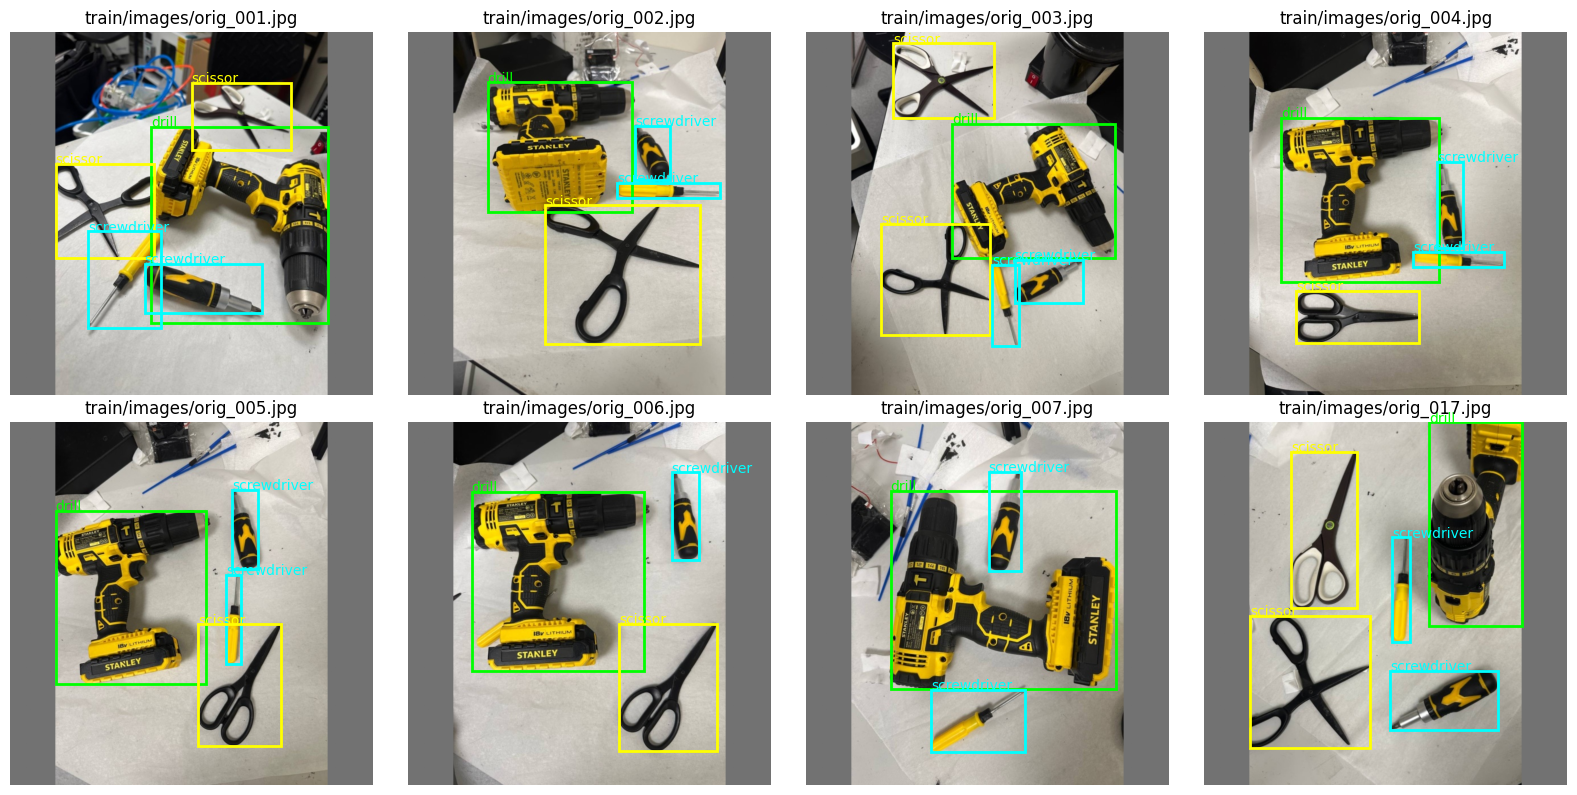

In [20]:
from matplotlib.patches import Rectangle

preview = ToolDataset(
    DATA_ROOT,
    manifest["splits"]["train"][:8],
    size=640,
    augment=False,
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
colours = ["lime", "yellow", "cyan"]

for index, ax in enumerate(axes.flat):
    image, labels = preview[index]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    rgb = (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(rgb)

    for class_id, cx, cy, width, height in labels.tolist():
        colour = colours[int(class_id)]
        left = (cx - width / 2) * 640
        top = (cy - height / 2) * 640
        ax.add_patch(Rectangle(
            (left, top), width * 640, height * 640,
            fill=False, edgecolor=colour, linewidth=2,
        ))
        ax.text(left, top, CLASSES[int(class_id)], color=colour)

    ax.set_title(preview.records[index]["image"])
    ax.axis("off")

plt.tight_layout()
fig.savefig(RUN_ROOT / "training_box_check.png", bbox_inches="tight")
plt.show()

{'epoch': 1, 'loss': 265.87169647216797, 'assignment_collisions': 0, 'val_map50': None}
{'epoch': 2, 'loss': 213.92658948898315, 'assignment_collisions': 0, 'val_map50': None}
{
  "best_val_map50": null,
  "best_epoch": 2,
  "train_seconds": 9.229022979736328,
  "parameters": 37192424,
  "config": {
    "lr": 0.0001,
    "weight_decay": 0.0001,
    "batch": 2,
    "epochs": 2,
    "patience": 2
  }
}


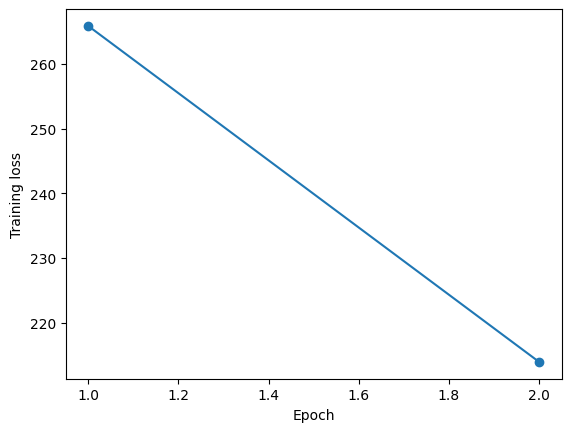

In [21]:
smoke_records = random.Random(SEED).sample(
    manifest["splits"]["train"],
    min(32, len(manifest["splits"]["train"])),
)

smoke_dir = RUN_ROOT / "smoke"
assert not smoke_dir.exists(), (
    "Smoke results already exist; choose a new output folder to rerun"
)

smoke_config = {
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "batch": 2,
    "epochs": 2,
    "patience": 2,
}

smoke_model = None
try:
    smoke_model, smoke_summary = fit(
        DATA_ROOT,
        smoke_records,
        None,
        anchors,
        smoke_config,
        smoke_dir,
    )
    print(json.dumps(smoke_summary, indent=2))
finally:
    if smoke_model is not None:
        del smoke_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

history = json.loads(
    (smoke_dir / "history.json").read_text(encoding="utf-8")
)
fig, ax = plt.subplots()
ax.plot(
    [row["epoch"] for row in history],
    [row["loss"] for row in history],
    marker="o",
)
ax.set(xlabel="Epoch", ylabel="Training loss")
fig.savefig(smoke_dir / "loss_curve.png", bbox_inches="tight")
plt.show()

## Real-data baseline: 358 training images, 92 validation images, 10 epochs


GPU: Tesla T4
Training images: 358
Validation images: 92
Output folder: /content/drive/MyDrive/EE3703GroupProject_person3_yolov2/runs/yolov2_20261103_090954_809552/baseline_10epochs
{'epoch': 1, 'loss': 61.62967575328976, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 2, 'loss': 17.005149385782595, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 3, 'loss': 14.512555812324226, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 4, 'loss': 14.244682277381088, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 5, 'loss': 13.369243304822698, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 6, 'loss': 12.656265647717694, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 7, 'loss': 12.978378013525596, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 8, 'loss': 12.49843159201425, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 9, 'loss': 12.467831406513406, 'assignment_collisions': 0, 'val_map50': 0.0}
{'epoch': 10, 'loss': 12.347049926246

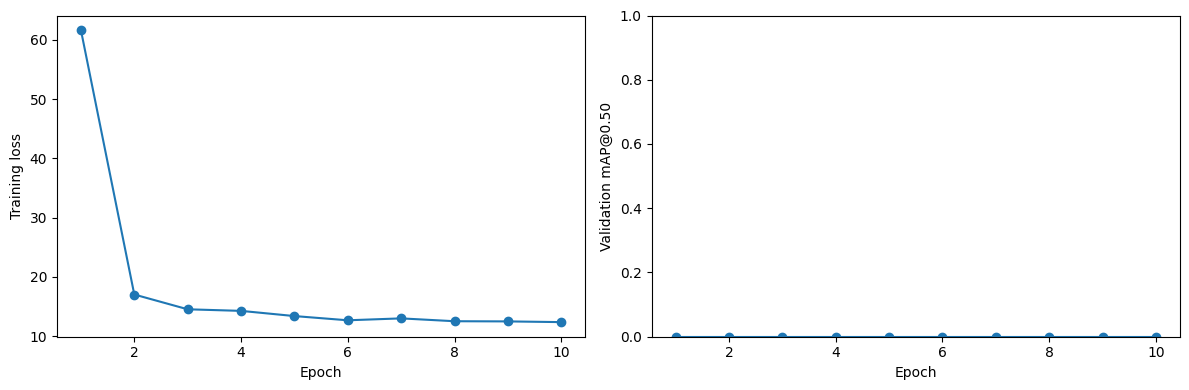

Saved files:
best.pt
history.json
summary.json
training_curves.png


In [22]:
assert torch.cuda.is_available(), "A GPU runtime is required"
assert "manifest" in globals(), "Run the data audit cell first"
assert "anchors" in globals(), "Run the anchor preparation cell first"

RUN_SEARCH = False
RUN_TRAINING = False
RUN_GOLD_TEST = False

baseline_dir = RUN_ROOT / "baseline_10epochs"
assert not baseline_dir.exists(), (
    "Baseline results already exist; use a new output folder to rerun"
)

baseline_config = {
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "batch": 2,
    "epochs": 10,
    "patience": 10,
}

print("GPU:", torch.cuda.get_device_name(0))
print("Training images:", len(manifest["splits"]["train"]))
print("Validation images:", len(manifest["splits"]["val"]))
print("Output folder:", baseline_dir)

baseline_model = None

try:
    baseline_model, baseline_summary = fit(
        DATA_ROOT,
        manifest["splits"]["train"],
        manifest["splits"]["val"],
        anchors,
        baseline_config,
        baseline_dir,
    )
    print(json.dumps(baseline_summary, indent=2))
finally:
    if baseline_model is not None:
        del baseline_model
    torch.cuda.empty_cache()

history = json.loads(
    (baseline_dir / "history.json").read_text(encoding="utf-8")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    [row["epoch"] for row in history],
    [row["loss"] for row in history],
    marker="o",
)
axes[0].set(xlabel="Epoch", ylabel="Training loss")

axes[1].plot(
    [row["epoch"] for row in history],
    [row["val_map50"] for row in history],
    marker="o",
)
axes[1].set(
    xlabel="Epoch",
    ylabel="Validation mAP@0.50",
    ylim=(0, 1),
)

plt.tight_layout()
fig.savefig(baseline_dir / "training_curves.png", bbox_inches="tight")
plt.show()

print("Saved files:")
for path in sorted(baseline_dir.iterdir()):
    print(path.name)